In [37]:
import random
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch 
import torch.nn as nn
import torch.optim as optim 

In [38]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(QNetwork, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64,64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )
    
    def forward(self, x):
        return self.fc(x)

In [184]:
import copy
from collections import deque

env = gym.make("Acrobot-v1", render_mode="rgb_array")
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

model = QNetwork(state_dim, action_dim)
optimizer = optim.Adam(model.parameters(), lr=5e-4)
criterion = nn.SmoothL1Loss()

target_model = copy.deepcopy(model)
target_model.eval()
target_update_every = 500

replay_buffer = deque(maxlen=50000)
batch_size = 64

episodes = 500
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.05

scores = []
total_steps = 0

In [185]:
print("Training...")
for e in range(episodes):
    state, _ = env.reset()
    total_reward = 0
    done = False
    
    while not done:
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                state_t = torch.FloatTensor(state).unsqueeze(0)
                q_values = model(state_t)
                action = torch.argmax(q_values).item()
        
        # Thực hiện action trong env
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        replay_buffer.append((state, action, reward, next_state, float(terminated)))
        
        state = next_state
        total_reward += reward
        total_steps += 1
        
        if len(replay_buffer) >= 2500:
            batch = random.sample(replay_buffer, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)
            states_t = torch.FloatTensor(np.array(states))
            actions_t = torch.LongTensor(actions).unsqueeze(1)
            rewards_t = torch.FloatTensor(rewards)
            next_states_t = torch.FloatTensor(np.array(next_states))            
            dones_t = torch.FloatTensor(dones)
            
            with torch.no_grad():
                max_next_q = target_model(next_states_t).max(dim=1)[0]
                target = rewards_t + gamma * max_next_q * (1 - dones_t)
            
            current_q = model(states_t).gather(1, actions_t).squeeze(1)
            
            loss = criterion(current_q, target)
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            optimizer.step()
        if total_steps % target_update_every == 0:
            target_model.load_state_dict(model.state_dict())
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    scores.append(total_reward)
    print(f"Episode: {e+1}/{episodes} | Score: {total_reward} | Epsilon: {epsilon:.2f}")

env.close()

Training...
Episode: 1/500 | Score: -500.0 | Epsilon: 0.99
Episode: 2/500 | Score: -500.0 | Epsilon: 0.99
Episode: 3/500 | Score: -500.0 | Epsilon: 0.99
Episode: 4/500 | Score: -500.0 | Epsilon: 0.98
Episode: 5/500 | Score: -500.0 | Epsilon: 0.98
Episode: 6/500 | Score: -269.0 | Epsilon: 0.97
Episode: 7/500 | Score: -500.0 | Epsilon: 0.97
Episode: 8/500 | Score: -500.0 | Epsilon: 0.96
Episode: 9/500 | Score: -500.0 | Epsilon: 0.96
Episode: 10/500 | Score: -500.0 | Epsilon: 0.95
Episode: 11/500 | Score: -500.0 | Epsilon: 0.95
Episode: 12/500 | Score: -500.0 | Epsilon: 0.94
Episode: 13/500 | Score: -500.0 | Epsilon: 0.94
Episode: 14/500 | Score: -500.0 | Epsilon: 0.93
Episode: 15/500 | Score: -500.0 | Epsilon: 0.93
Episode: 16/500 | Score: -473.0 | Epsilon: 0.92
Episode: 17/500 | Score: -500.0 | Epsilon: 0.92
Episode: 18/500 | Score: -427.0 | Epsilon: 0.91
Episode: 19/500 | Score: -500.0 | Epsilon: 0.91
Episode: 20/500 | Score: -500.0 | Epsilon: 0.90
Episode: 21/500 | Score: -500.0 | Eps

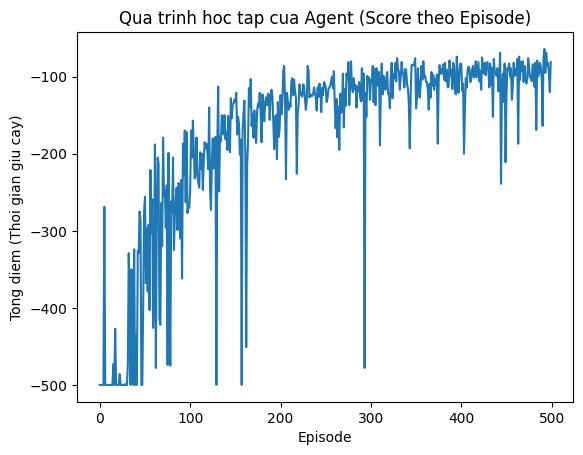

In [186]:
plt.plot(scores)
plt.title("Qua trinh hoc tap cua Agent (Score theo Episode)")
plt.xlabel("Episode")
plt.ylabel("Tong diem (Thoi gian giu cay)")
plt.show()

In [187]:
# Đánh giá sau huấn luyện: chạy policy THUẦN GREEDY (epsilon = 0, không khám phá, không học)
def evaluate(model, n_episodes=20, render=False):
    # env cũ đã bị env.close() ở cell huấn luyện nên tạo env mới.
    # render=True sẽ mở cửa sổ để xem agent chơi; render=False thì chạy nhanh.
    eval_env = gym.make("Acrobot-v1", render_mode="human" if render else None)
    model.eval()                       # chuyển sang chế độ đánh giá
    results = []
    for _ in range(n_episodes):
        state, _ = eval_env.reset()
        done, total = False, 0
        while not done:
            with torch.no_grad():      # không tính gradient vì không huấn luyện
                action = model(torch.FloatTensor(state).unsqueeze(0)).argmax().item()
            state, reward, terminated, truncated, _ = eval_env.step(action)
            done = terminated or truncated
            total += reward
        results.append(total)
    eval_env.close()
    model.train()
    return results

In [188]:
evaluate(model, n_episodes=3, render=True)


[-500.0, -500.0, -500.0]

In [19]:
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

env = Monitor(gym.make("Acrobot-v1"))
eval_env = Monitor(gym.make("Acrobot-v1"))

model = DQN(
    "MlpPolicy", env,
    learning_rate=6.3e-4,
    buffer_size=50_000,
    learning_starts=0,
    batch_size=128,
    gamma=0.99,
    train_freq=4,
    gradient_steps=-1,
    target_update_interval=250,
    exploration_fraction=0.12,
    exploration_final_eps=0.1,
    policy_kwargs=dict(net_arch=[256, 256]),
    seed=0, verbose=1,
    tensorboard_log="./logs",
)
# model.learn(total_timesteps=100_000)
# model.save("dqn_acrobot")

# mean_r, std_r = evaluate_policy(model, eval_env, n_eval_episodes=100)
# print(f"Return: {mean_r:.1f} +/- {std_r:.1f}")

Using cuda device
Wrapping the env in a DummyVecEnv.


In [20]:
import gymnasium as gym
from stable_baselines3 import DQN

env = gym.make("Acrobot-v1", render_mode="human")
model = DQN.load("dqn_acrobot")

for ep in range(5):
    obs, _ = env.reset()
    done, steps = False, 0
    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, _ = env.step(int(action))
        done = terminated or truncated
        steps += 1
    print(f"Episode {ep}: {steps} steps")

env.close()

FileNotFoundError: [Errno 2] No such file or directory: 'dqn_acrobot.zip'

# Thử nghiệm phương pháp PPO

In [1]:
print("Done")

Done


In [2]:
import gymnasium as gym
import numpy as np 
import torch 
import torch.nn as nn 
from torch.distributions import Categorical

In [ ]:
from torch.distributions import Independent, Normal

class ActorCritic(nn.Module):
    # continuous=False: action rời rạc (Categorical). continuous=True: action liên tục (Gaussian, log_std học được).
    # Với continuous=False tên tham số giữ nguyên nên vẫn nạp được checkpoint cũ.
    def __init__(self, obs_dim, n_actions, continuous=False, *args, **kwargs):
        super().__init__()
        self.continuous = continuous
        self.actor = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, n_actions)
        )
        self.critic = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
        if continuous:
            self.log_std = nn.Parameter(torch.zeros(n_actions))
    
    def forward(self, x):
        out = self.actor(x)
        if self.continuous:
            dist = Independent(Normal(out, self.log_std.exp()), 1)
        else:
            dist = Categorical(logits=out)
        value = self.critic(x).squeeze(-1)
        return dist, value

In [7]:
# ---- Hyperparameters ----
T, K, MB = 2048, 10, 64
GAMMA, LAMBDA, CLIP_EPS = 0.99, 0.95, 0.2
LR, C1, C2 = 3e-4, 0.5, 0.01
TOTAL_STEPS = 100_000

env = gym.make("Acrobot-v1")
model = ActorCritic(env.observation_space.shape[0], env.action_space.n)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, eps=1e-5)

state, _ = env.reset(seed=0)
ep_total_reward, ep_return = 0.0, []
n_updates = TOTAL_STEPS // T
print(f"Training for {TOTAL_STEPS} steps, {n_updates} updates, {T} steps per update")

best_avg = -np.inf
log = {"step": [], "avg_return": [], "ent": [], "kl": [], "clipfrac": [], "v_loss": []}
ep_log = [] # (số bước tại lúc episode kết thúc, return của episode)

for update in range(n_updates):
    B_states = torch.zeros(T, env.observation_space.shape[0])
    B_actions = torch.zeros(T, dtype=torch.long)
    B_logprobs = torch.zeros(T)
    B_rewards = torch.zeros(T)
    B_dones = torch.zeros(T)
    B_val = torch.zeros(T)
    
    for t in range(T):
        state = torch.as_tensor(state, dtype=torch.float32)
        with torch.no_grad():
            dist, value = model(state)
            action = dist.sample()
            logprob = dist.log_prob(action)
        
        next_state, reward, terminated, truncated, _ = env.step(action.item())
        ep_total_reward += reward
        
        if truncated and not terminated:
            with torch.no_grad():
                _, v_last = model(torch.as_tensor(next_state, dtype=torch.float32))
            reward = reward + GAMMA * v_last.item()
        
        done = terminated or truncated
        B_states[t] = state
        B_actions[t] = action
        B_logprobs[t] = logprob
        B_rewards[t] = reward
        B_dones[t] = float(done)
        B_val[t] = value.item()

        state = next_state
        if done:
            ep_return.append(ep_total_reward)
            ep_log.append((update * T + t + 1, ep_total_reward))
            ep_total_reward = 0.0
            state, _ = env.reset()
    
    # ==== Pha 2: GAE ====
    with torch.no_grad():
        _, last_value = model(torch.as_tensor(state, dtype=torch.float32))
    B_advantages = torch.zeros(T)
    gae = 0.0
    for t in reversed(range(T)):
        next_value = last_value if t == T - 1 else B_val[t + 1]
        nonterm = 1.0 - B_dones[t]
        delta = B_rewards[t] + GAMMA * next_value * nonterm - B_val[t]
        gae = delta + GAMMA * LAMBDA * nonterm * gae
        B_advantages[t] = gae
    
    targets = B_advantages + B_val
    B_advantages = (B_advantages - B_advantages.mean()) / (B_advantages.std() + 1e-8)
    
    # ==== Pha 3: PPO update ====
    for _ in range(K):
        perm = torch.randperm(T)
        for i in range(0, T, MB):
            idx = perm[i:i + MB]
            dist, value = model(B_states[idx])
            logprobs = dist.log_prob(B_actions[idx])
            ratios = torch.exp(logprobs - B_logprobs[idx])
            
            pg_loss = -torch.min(
                ratios * B_advantages[idx],
                torch.clamp(ratios, 1 - CLIP_EPS, 1 + CLIP_EPS) * B_advantages[idx]
            ).mean()
            v_loss = ((value - targets[idx]) ** 2).mean()
            entropy = dist.entropy().mean()
            loss = pg_loss + C1 * v_loss - C2 * entropy
            
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()
    
    with torch.no_grad():
        approx_kl = (B_logprobs[idx] -logprobs).mean().item()
        clip = ((ratios - 1).abs() > CLIP_EPS).float().mean().item()
    
    avg = np.mean(ep_return[-10:]) if len(ep_return) >= 10 else np.mean(ep_return)
    
    log["step"].append((update + 1) * T)
    log["avg_return"].append(avg)
    log["ent"].append(entropy.item())
    log["kl"].append(approx_kl)
    log["clipfrac"].append(clip)
    log["v_loss"].append(v_loss.item())
    
    if avg > best_avg:
        best_avg = avg
        torch.save(model.state_dict(), "ppo_acrobot.pt")
    
    print(f"Update {update + 1}/{n_updates} | Avg Return: {avg:.2f} | Entropy: {entropy.item():.3f} | KL: {approx_kl:.5f} | ClipFrac: {clip:.3f} | V Loss: {v_loss.item():.5f}")

Training for 100000 steps, 48 updates, 2048 steps per update
Update 1/48 | Avg Return: -500.00 | Entropy: 1.092 | KL: 0.02050 | ClipFrac: 0.031 | V Loss: 45.81096
Update 2/48 | Avg Return: -500.00 | Entropy: 1.077 | KL: 0.02045 | ClipFrac: 0.125 | V Loss: 61.36070
Update 3/48 | Avg Return: -500.00 | Entropy: 1.041 | KL: 0.02718 | ClipFrac: 0.078 | V Loss: 49.94958
Update 4/48 | Avg Return: -500.00 | Entropy: 1.053 | KL: 0.01488 | ClipFrac: 0.203 | V Loss: 39.99135
Update 5/48 | Avg Return: -500.00 | Entropy: 1.017 | KL: 0.02800 | ClipFrac: 0.125 | V Loss: 27.49492
Update 6/48 | Avg Return: -463.60 | Entropy: 1.027 | KL: 0.00478 | ClipFrac: 0.031 | V Loss: 29.53286
Update 7/48 | Avg Return: -424.80 | Entropy: 1.011 | KL: 0.00131 | ClipFrac: 0.109 | V Loss: 47.69999
Update 8/48 | Avg Return: -354.90 | Entropy: 0.937 | KL: 0.01323 | ClipFrac: 0.141 | V Loss: 78.33304
Update 9/48 | Avg Return: -238.70 | Entropy: 0.925 | KL: -0.00015 | ClipFrac: 0.156 | V Loss: 47.23530
Update 10/48 | Avg R

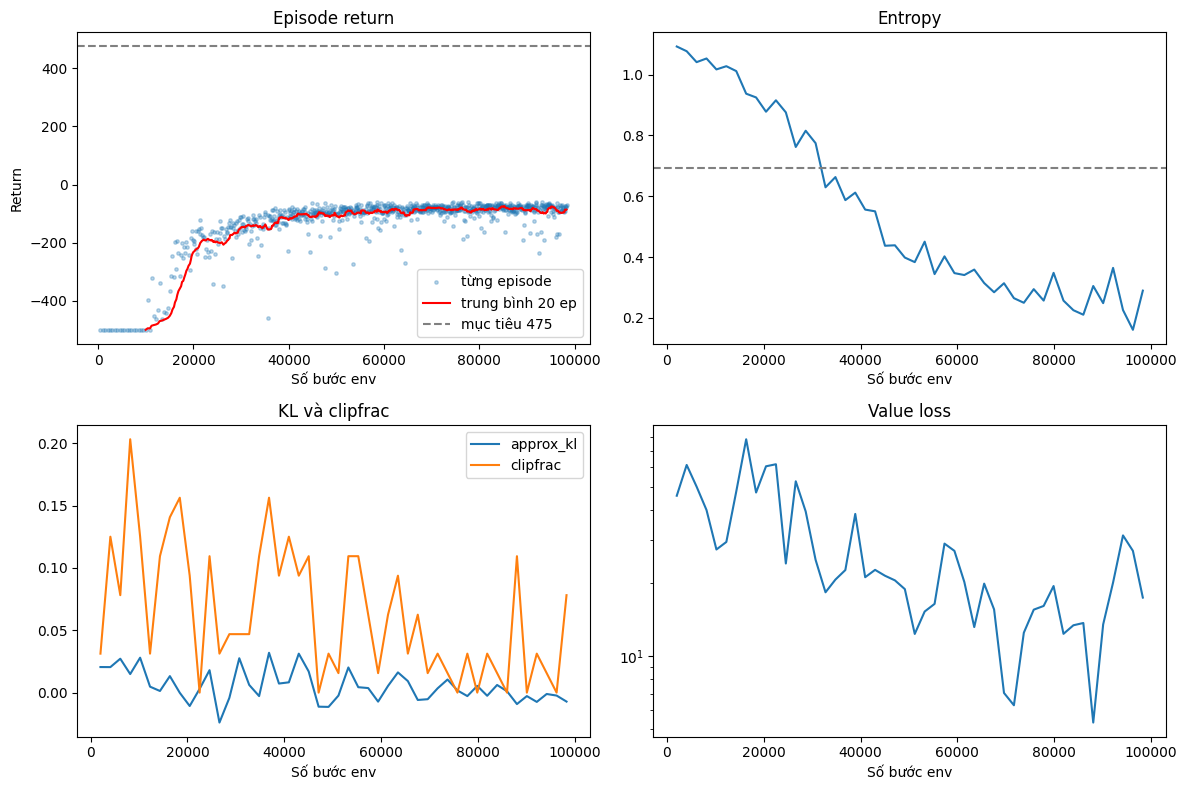

In [8]:
import matplotlib.pyplot as plt

def plot_training(log, ep_log, window=20):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # 1. Return: điểm mờ = từng episode, đường đậm = trung bình trượt
    steps, rets = zip(*ep_log)
    axes[0, 0].scatter(steps, rets, s=6, alpha=0.3, label="từng episode")
    if len(rets) >= window:
        ma = np.convolve(rets, np.ones(window) / window, mode="valid")
        axes[0, 0].plot(steps[window - 1:], ma, color="red", label=f"trung bình {window} ep")
    axes[0, 0].axhline(475, ls="--", color="gray", label="mục tiêu 475")
    axes[0, 0].set(title="Episode return", xlabel="Số bước env", ylabel="Return")
    axes[0, 0].legend()

    # 2. Entropy
    axes[0, 1].plot(log["step"], log["ent"])
    axes[0, 1].axhline(np.log(2), ls="--", color="gray")   # entropy tối đa của 2 action
    axes[0, 1].set(title="Entropy", xlabel="Số bước env")

    # 3. KL và clipfrac
    axes[1, 0].plot(log["step"], log["kl"], label="approx_kl")
    axes[1, 0].plot(log["step"], log["clipfrac"], label="clipfrac")
    axes[1, 0].set(title="KL và clipfrac", xlabel="Số bước env")
    axes[1, 0].legend()

    # 4. Value loss
    axes[1, 1].plot(log["step"], log["v_loss"])
    axes[1, 1].set(title="Value loss", xlabel="Số bước env", yscale="log")

    plt.tight_layout()
    plt.savefig("ppo_cartpole_curves.png", dpi=150)
    plt.show()

plot_training(log, ep_log)

In [ ]:
def watch(model, episodes=5, greedy=True):
    env = gym.make("Acrobot-v1", render_mode="human")
    for ep in range(episodes):
        state, _ = env.reset()
        total, done = 0.0, False
        while not done:
            s = torch.as_tensor(state, dtype=torch.float32)
            with torch.no_grad():
                dist, _ = model(s)
                action = dist.probs.argmax() if greedy else dist.sample()
            state, r, terminated, truncated, _ = env.step(action.item())
            total += r
            done = terminated or truncated
        print(f"episode {ep + 1}: return = {total}")
    env.close()

episode 1: return = -69.0
episode 2: return = -80.0
episode 3: return = -70.0
episode 4: return = -71.0
episode 5: return = -96.0


In [14]:
def make_model(env):
    """Tạo ActorCritic phù hợp với env (action rời rạc hoặc liên tục, obs là vector)."""
    obs_dim = int(np.prod(env.observation_space.shape))
    if isinstance(env.action_space, gym.spaces.Discrete):
        return ActorCritic(obs_dim, env.action_space.n)
    return ActorCritic(obs_dim, env.action_space.shape[0], continuous=True)


def train_ppo(env_id, n_updates=50, model=None, load_path=None, save_path=None,
              T=2048, K=10, MB=64, gamma=0.99, lam=0.95, clip_eps=0.2,
              lr=3e-4, c1=0.5, c2=0.01, seed=0, verbose=True, **env_kwargs):
    """Train PPO trên env_id.
    - model: truyền model có sẵn để train tiếp; None thì tạo mới (có thể nạp từ load_path).
    - save_path: lưu model có avg return (10 episode gần nhất) tốt nhất.
    Trả về (model, log, ep_log)."""
    env = gym.make(env_id, **env_kwargs)
    continuous = isinstance(env.action_space, gym.spaces.Box)
    if model is None:
        model = make_model(env)
        if load_path:
            model.load_state_dict(torch.load(load_path))
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, eps=1e-5)

    obs_dim = int(np.prod(env.observation_space.shape))
    act_shape = env.action_space.shape if continuous else ()
    act_dtype = torch.float32 if continuous else torch.long
    to_t = lambda x: torch.as_tensor(np.asarray(x).flatten(), dtype=torch.float32)

    state, _ = env.reset(seed=seed)
    ep_total_reward, ep_return, ep_log = 0.0, [], []
    best_avg = -np.inf
    log = {"step": [], "avg_return": [], "ent": [], "kl": [], "clipfrac": [], "v_loss": []}

    for update in range(n_updates):
        B_states = torch.zeros(T, obs_dim)
        B_actions = torch.zeros((T, *act_shape), dtype=act_dtype)
        B_logprobs, B_rewards = torch.zeros(T), torch.zeros(T)
        B_dones, B_val = torch.zeros(T), torch.zeros(T)

        # ==== Pha 1: thu thập dữ liệu ====
        for t in range(T):
            s = to_t(state)
            with torch.no_grad():
                dist, value = model(s)
                action = dist.sample()
                logprob = dist.log_prob(action)

            env_action = np.clip(action.numpy(), env.action_space.low, env.action_space.high) if continuous else action.item()
            next_state, reward, terminated, truncated, _ = env.step(env_action)
            ep_total_reward += reward

            if truncated and not terminated:   # bootstrap khi bị cắt do time limit
                with torch.no_grad():
                    reward = reward + gamma * model(to_t(next_state))[1].item()

            done = terminated or truncated
            B_states[t], B_actions[t], B_logprobs[t] = s, action, logprob
            B_rewards[t], B_dones[t], B_val[t] = reward, float(done), value.item()

            state = next_state
            if done:
                ep_return.append(ep_total_reward)
                ep_log.append((update * T + t + 1, ep_total_reward))
                ep_total_reward = 0.0
                state, _ = env.reset()

        # ==== Pha 2: GAE ====
        with torch.no_grad():
            last_value = model(to_t(state))[1]
        B_adv = torch.zeros(T)
        gae = 0.0
        for t in reversed(range(T)):
            next_value = last_value if t == T - 1 else B_val[t + 1]
            nonterm = 1.0 - B_dones[t]
            delta = B_rewards[t] + gamma * next_value * nonterm - B_val[t]
            gae = delta + gamma * lam * nonterm * gae
            B_adv[t] = gae
        targets = B_adv + B_val
        B_adv = (B_adv - B_adv.mean()) / (B_adv.std() + 1e-8)

        # ==== Pha 3: PPO update ====
        for _ in range(K):
            perm = torch.randperm(T)
            for i in range(0, T, MB):
                idx = perm[i:i + MB]
                dist, value = model(B_states[idx])
                logprobs = dist.log_prob(B_actions[idx])
                ratios = torch.exp(logprobs - B_logprobs[idx])

                pg_loss = -torch.min(
                    ratios * B_adv[idx],
                    torch.clamp(ratios, 1 - clip_eps, 1 + clip_eps) * B_adv[idx]
                ).mean()
                v_loss = ((value - targets[idx]) ** 2).mean()
                entropy = dist.entropy().mean()
                loss = pg_loss + c1 * v_loss - c2 * entropy

                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 0.5)
                optimizer.step()

        with torch.no_grad():
            approx_kl = (B_logprobs[idx] - logprobs).mean().item()
            clip = ((ratios - 1).abs() > clip_eps).float().mean().item()

        avg = np.mean(ep_return[-10:]) if ep_return else float("nan")
        for k, v in zip(log, [(update + 1) * T, avg, entropy.item(), approx_kl, clip, v_loss.item()]):
            log[k].append(v)

        if save_path and avg > best_avg:
            best_avg = avg
            torch.save(model.state_dict(), save_path)

        if verbose:
            print(f"Update {update + 1}/{n_updates} | Avg Return: {avg:.2f} | Entropy: {entropy.item():.3f} | KL: {approx_kl:.5f} | ClipFrac: {clip:.3f} | V Loss: {v_loss.item():.5f}")

    env.close()
    return model, log, ep_log


# Train tiếp model cũ thêm 50 updates:
model, log2, ep_log2 = train_ppo("Acrobot-v1", n_updates=50, load_path="ppo_acrobot.pt", save_path="ppo_acrobot_cont.pt", seed=1)

# Train tiếp thêm nữa từ model đang có trong bộ nhớ:
# model, log3, ep_log3 = train_ppo("Acrobot-v1", n_updates=50, model=model)

# Env khác (chỉ cần obs là vector):
# pend_model, _, _ = train_ppo("Pendulum-v1", n_updates=200)
# cart_model, _, _ = train_ppo("CartPole-v1", n_updates=50)


Update 1/50 | Avg Return: -74.20 | Entropy: 0.205 | KL: -0.00387 | ClipFrac: 0.031 | V Loss: 11.56839
Update 2/50 | Avg Return: -83.40 | Entropy: 0.267 | KL: 0.00509 | ClipFrac: 0.016 | V Loss: 8.60226
Update 3/50 | Avg Return: -93.30 | Entropy: 0.267 | KL: 0.00175 | ClipFrac: 0.031 | V Loss: 20.18540
Update 4/50 | Avg Return: -98.60 | Entropy: 0.197 | KL: 0.00236 | ClipFrac: 0.000 | V Loss: 24.16718
Update 5/50 | Avg Return: -80.90 | Entropy: 0.224 | KL: 0.00239 | ClipFrac: 0.016 | V Loss: 11.11915
Update 6/50 | Avg Return: -80.50 | Entropy: 0.247 | KL: 0.03005 | ClipFrac: 0.047 | V Loss: 21.16146
Update 7/50 | Avg Return: -92.80 | Entropy: 0.179 | KL: 0.00706 | ClipFrac: 0.031 | V Loss: 13.06809
Update 8/50 | Avg Return: -90.80 | Entropy: 0.214 | KL: -0.00503 | ClipFrac: 0.000 | V Loss: 18.00046
Update 9/50 | Avg Return: -78.00 | Entropy: 0.134 | KL: -0.00549 | ClipFrac: 0.031 | V Loss: 10.46954
Update 10/50 | Avg Return: -93.70 | Entropy: 0.185 | KL: 0.00280 | ClipFrac: 0.031 | V Lo

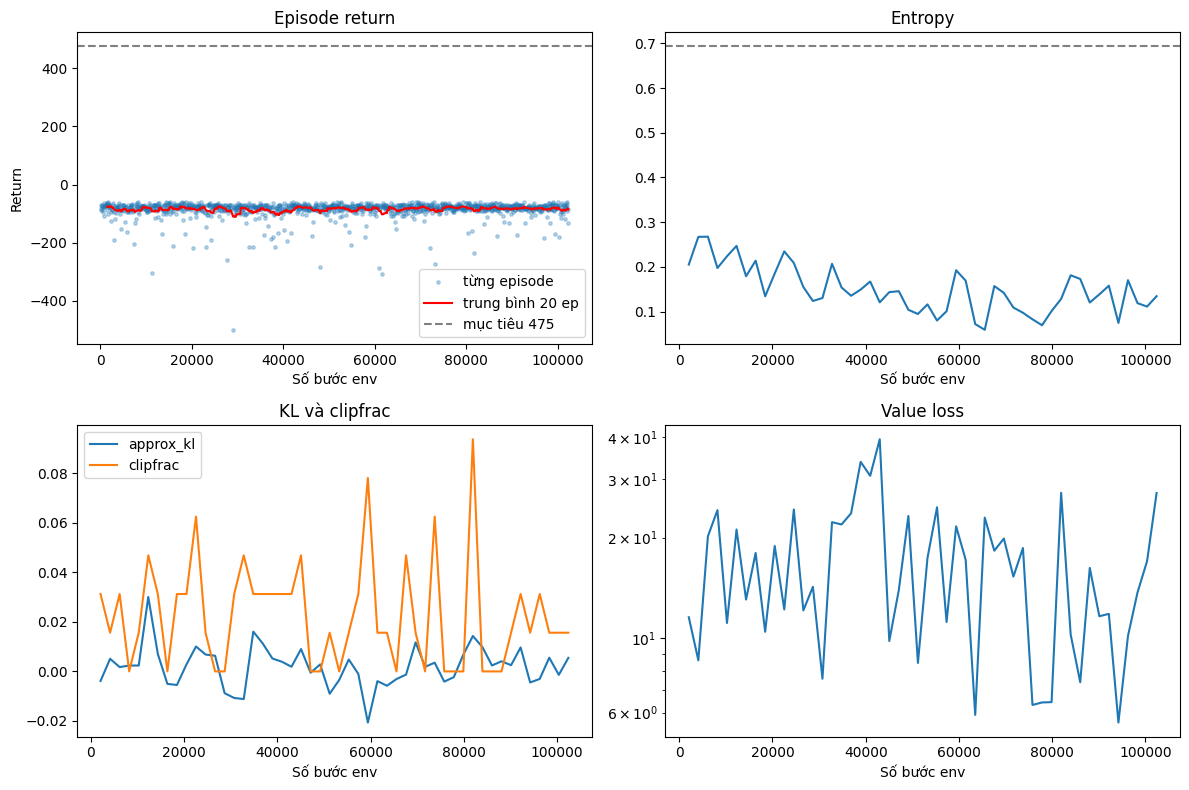

In [15]:
plot_training(log2, ep_log2)

In [16]:
# Nạp model đã lưu và xem
best = ActorCritic(6, 3)
best.load_state_dict(torch.load("ppo_acrobot.pt"))
best.eval()
watch(best, episodes=5, greedy=True)

episode 1: return = -77.0
episode 2: return = -85.0
episode 3: return = -85.0
episode 4: return = -79.0
episode 5: return = -72.0


In [21]:
for p in ["ppo_acrobot.pt", "ppo_acrobot_cont.pt"]:
    m = ActorCritic(6, 3); m.load_state_dict(torch.load(p)); m.eval()
    env = gym.make("Acrobot-v1"); rets = []
    for _ in range(100):
        s, _ = env.reset(); done, tot = False, 0
        while not done:
            with torch.no_grad(): a = m(torch.as_tensor(s, dtype=torch.float32))[0].probs.argmax().item()
            s, r, te, tr, _ = env.step(a); tot += r; done = te or tr
        rets.append(tot)
    print(p, np.mean(rets), np.std(rets))

ppo_acrobot.pt -83.89 20.30856715772927
ppo_acrobot_cont.pt -85.76 23.850417187126936
